# Adaptive Noise Cancellation using from LMS and MLP Neural Network
**AI/ML CIE 3 Project**

**Idea:** A noise-cancelling filter is a tiny machine-learning model. Its weights are learned from data by gradient descent.
In this notebook we treat the LMS filter as a one-neuron model, compare it with other learning methods, study the effect of
hyper-parameters, and additionally show that a small neural network beats LMS when the noise is non-linear.



1. Importing all relevant libraries

In [ ]:
!pip -q install librosa soundfile gradio

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import soundfile as sf
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import Audio, display

warnings.filterwarnings("ignore")
print("Libraries imported.")

Libraries imported.


2. Setting up hyper-parameters and audio input

In [ ]:
SR            = 8000   # sampling rate we resample everything to (Hz). Lower = faster
SECONDS       = 15     # how many seconds of the audio we use
INPUT_SNR_DB  = 5      # how loud the noise is compared to the music where 5 dB is fairly noisy
TRAIN_FRAC    = 0.4    # first 40% of the audio = training part, last 60% = test part
L             = 8      # filter length = number of past reference samples the model looks at
MU            = 0.01   # learning rate of LMS

H = np.array([0.8, 0.35, -0.2, 0.12, -0.07, 0.04, -0.02, 0.01])

NOISE_FILE = None

try:
    from google.colab import files
    print("Upload the CLEAN audio (music or speech, 10-20 seconds, wav/mp3):")
    up = files.upload()
    AUDIO_FILE = list(up.keys())[0]
except ImportError:
    AUDIO_FILE = "your_audio.wav"
print("Using audio file:", AUDIO_FILE)

Upload the CLEAN audio (music or speech, 10-20 seconds, wav/mp3):


Saving clean_music_like.wav to clean_music_like (1).wav
Using audio file: clean_music_like (1).wav


## Part A - Building the data
We never have a "clean vs noisy" dataset ready-made, so we **create our own**:
clean audio + noise that reaches the microphone through a "room" = noisy recording.
The reference microphone hears only the noise *source*. Two kinds of noise:
* **linear** - the room just mixes and delays the noise
* **nonlinear** - the speaker/amplifier also distorts the noise (clipping + squaring), which is closer to real life

3. Functions to create the noisy audio from the clean recording and to turn all previous samples into a table to use as inputs for the model.

In [ ]:
def load_audio(path, sr=SR, seconds=SECONDS):
    y, _ = librosa.load(path, sr=sr, mono=True, duration=seconds)
    assert len(y) > 5 * sr, "Please use an audio file longer than 5 seconds."
    return y / (np.sqrt(np.mean(y ** 2)) + 1e-12)

def make_reference(n, noise_file=None, seed=0):
    if noise_file is None:
        r = np.random.default_rng(seed).standard_normal(n)
    else:
        r, _ = librosa.load(noise_file, sr=SR, mono=True)
        r = np.tile(r, int(np.ceil(n / len(r))))[:n]
    return (r - r.mean()) / (r.std() + 1e-12)

def build_scenario(clean, kind="linear", snr_db=INPUT_SNR_DB, noise_file=None):
    n = len(clean)
    ref = make_reference(n, noise_file)
    z = np.convolve(ref, H)[:n]
    if kind == "linear":
        noise = z
    else:                                                           # distortion: clipping + squaring
        noise = np.tanh(1.5 * z) + 0.5 * (z ** 2 - np.mean(z ** 2))
    # scale the noise so that the input SNR is exactly snr_db
    gain = np.sqrt(np.mean(clean ** 2) / (10 ** (snr_db / 10)) / np.mean(noise ** 2))
    noise = noise * gain
    if kind == "linear":
        ref = ref * gain
    return dict(clean=clean, ref=ref, noise=noise, noisy=clean + noise,
                split=int(TRAIN_FRAC * n), kind=kind)

def delay_matrix(ref, length):
    # Row n = [ref[n], ref[n-1], ..., ref[n-length+1]]  -> the model's INPUT FEATURES
    padded = np.concatenate([np.zeros(length - 1), ref])
    return sliding_window_view(padded, length)[:, ::-1].copy()

def snr_db(clean, out):
    # how much stronger the wanted signal is than the leftover error (bigger = better)
    return 10 * np.log10(np.mean(clean ** 2) / (np.mean((out - clean) ** 2) + 1e-12))

def play(x, scale):
    display(Audio(np.nan_to_num(x) * scale, rate=SR, normalize=False))

## Part B - The learning algorithms
All of the algorithms learn weights `w` so that `w . (recent reference samples)` is as close as possible to the noise in the recording.
* **LMS** - gradient descent, one sample at a time
* **NLMS** - LMS whose step size adapts to how loud the input is (more stable)
* **RLS** - a "smarter but heavier" learner that uses a memory of past data
* **Linear regression** - the textbook ML way: solve for the best weights directly on all training data
* **Neural network (MLP)** - can learn curved (non-linear) relationships

5. Code for all the learning algorithms used in this project i.e LMS, RLS and MLP

In [ ]:
def lms(X, d, mu, normalized=False, eps=1e-6):
    # One-neuron model trained by stochastic gradient descent, one sample at a time.
    n, k = X.shape
    w = np.zeros(k)
    err = np.zeros(n); hist = np.zeros((n, k))
    for i in range(n):
        x = X[i]
        e = d[i] - w @ x                     # prediction error  (target - prediction)
        step = mu / (eps + x @ x) if normalized else mu
        w = w + step * e * x                 # gradient-descent update:  w <- w + mu * e * x
        err[i] = e; hist[i] = w
    return w, err, hist

def rls(X, d, lam=0.999, delta=0.01):
    # Recursive Least Squares: keeps a 'confidence matrix' P, so it learns much faster than LMS.
    n, k = X.shape
    w = np.zeros(k); P = np.eye(k) / delta
    for i in range(n):
        x = X[i]; Px = P @ x
        g = Px / (lam + x @ Px)
        w = w + g * (d[i] - w @ x)
        P = (P - np.outer(g, Px)) / lam
        P = (P + P.T) / 2
    return w

def fit_predict(method, Xtr, dtr, Xte, mu=MU):
    # Train on the TRAIN part, then predict the noise on the unseen TEST part.
    extra = None
    with np.errstate(all="ignore"):
        if method == "LMS":
            w, _, _ = lms(Xtr, dtr, mu); pred, extra = Xte @ w, w
        elif method == "NLMS":
            w, _, _ = lms(Xtr, dtr, mu, normalized=True); pred, extra = Xte @ w, w
        elif method == "RLS":
            w = rls(Xtr, dtr); pred, extra = Xte @ w, w
        elif method == "Linear regression":
            m = LinearRegression(fit_intercept=False).fit(Xtr, dtr); pred, extra = Xte @ m.coef_, m.coef_
        elif method == "Neural network":
            m = make_pipeline(StandardScaler(),
                              MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu",
                                           batch_size=256, learning_rate_init=1e-3, max_iter=60,
                                           early_stopping=True, n_iter_no_change=6, random_state=0))
            m.fit(Xtr, dtr); pred, extra = m.predict(Xte), m[-1].loss_curve_
        else:
            raise ValueError(method)
    return np.nan_to_num(pred), extra

## Part C - Train on one part, test on unseen audio, compare all models

6. Runs every algorithm on both linear and non-linear noise and prints the results and observations in tabular format

In [ ]:
METHODS = [("LMS, 3 taps (original calculus project)", "LMS", 0.01, 3),
           ("LMS", "LMS", 0.01, L),
           ("NLMS", "NLMS", 0.05, L),
           ("RLS", "RLS", None, L),
           ("Linear regression", "Linear regression", None, L),
           ("Neural network", "Neural network", None, L)]

clean = load_audio(AUDIO_FILE)
SIG, OUT, EXTRA, TABLE = {}, {}, {}, {}

for kind in ["linear", "nonlinear"]:
    sig = build_scenario(clean, kind, noise_file=NOISE_FILE)
    k = sig["split"]
    X = delay_matrix(sig["ref"], L)
    d, c = sig["noisy"], sig["clean"]
    rows = {"No filter (noisy input)": snr_db(c[k:], d[k:])}
    OUT[kind] = {"No filter (noisy input)": d[k:]}
    EXTRA[kind] = {}
    for name, method, mu, taps in METHODS:
        Xk = X[:, :taps]
        pred, extra = fit_predict(method, Xk[:k], d[:k], Xk[k:], mu if mu else MU)
        out = d[k:] - pred
        rows[name] = snr_db(c[k:], out)
        OUT[kind][name] = out; EXTRA[kind][name] = extra
    SIG[kind] = sig
    base = rows["No filter (noisy input)"]
    TABLE[kind] = pd.DataFrame({"SNR on TEST audio (dB)": rows,
                                "Improvement (dB)": {m: v - base for m, v in rows.items()}}).round(2)
    print(f"\n===== {kind.upper()} noise  (higher SNR = cleaner) =====")
    print(TABLE[kind])


===== LINEAR noise  (higher SNR = cleaner) =====
                                         SNR on TEST audio (dB)  \
No filter (noisy input)                                    4.99   
LMS, 3 taps (original calculus project)                   19.43   
LMS                                                       23.84   
NLMS                                                      13.44   
RLS                                                       32.69   
Linear regression                                         36.43   
Neural network                                            21.49   

                                         Improvement (dB)  
No filter (noisy input)                              0.00  
LMS, 3 taps (original calculus project)             14.44  
LMS                                                 18.85  
NLMS                                                 8.44  
RLS                                                 27.69  
Linear regression                                   3

  7. Bar chart visualisation of all relevant observational results

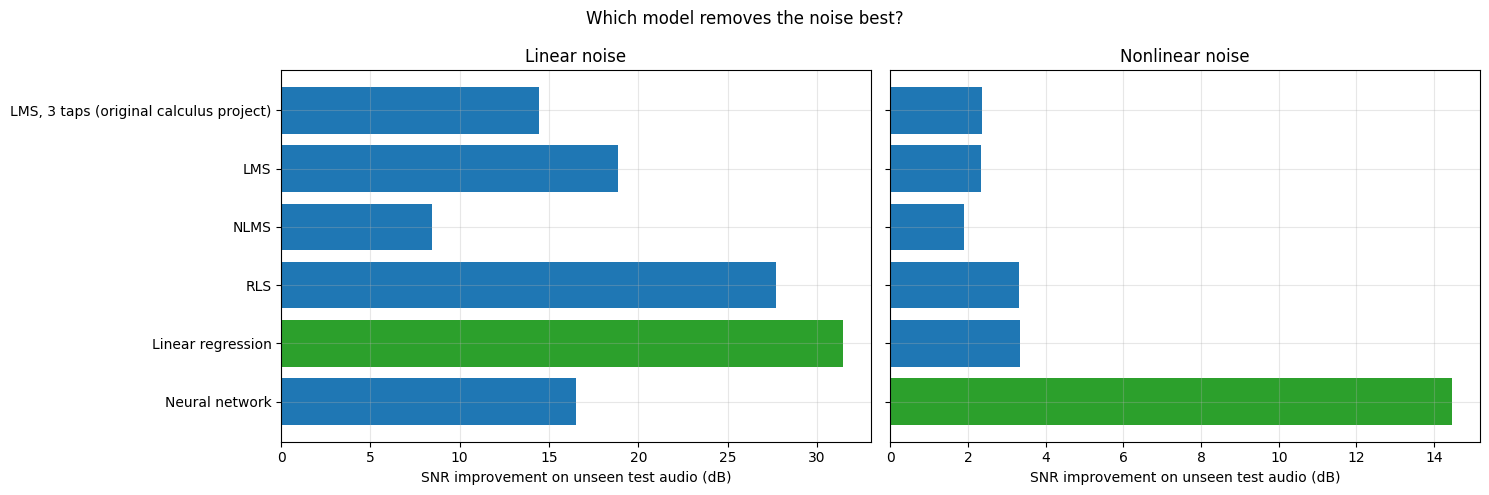

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for a, kind in zip(ax, ["linear", "nonlinear"]):
    t = TABLE[kind]["Improvement (dB)"].drop("No filter (noisy input)")
    a.barh(t.index[::-1], t.values[::-1], color=["tab:green" if v == t.max() else "tab:blue" for v in t.values[::-1]])
    a.set_title(f"{kind.capitalize()} noise"); a.set_xlabel("SNR improvement on unseen test audio (dB)"); a.grid(alpha=.3)
plt.suptitle("Which model removes the noise best?"); plt.tight_layout(); plt.show()

8. Waveform visualisation of the audio

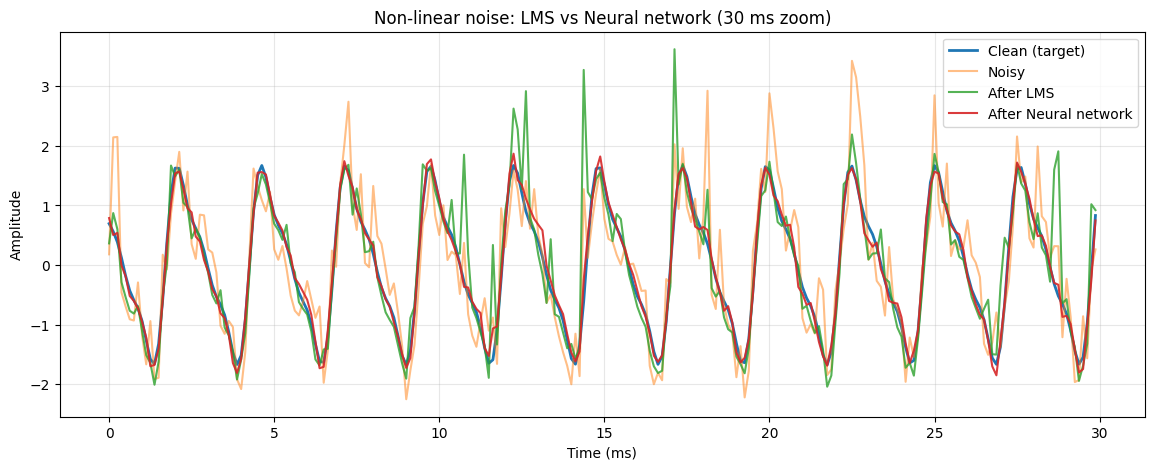

In [ ]:
kind = "nonlinear"; k = SIG[kind]["split"]
a, b = 2000, 2000 + int(0.03 * SR)
tt = np.arange(b - a) / SR * 1000
plt.figure(figsize=(14, 5))
plt.plot(tt, SIG[kind]["clean"][k + a:k + b], label="Clean (target)", lw=2)
plt.plot(tt, OUT[kind]["No filter (noisy input)"][a:b], label="Noisy", alpha=.5)
plt.plot(tt, OUT[kind]["LMS"][a:b], label="After LMS", alpha=.8)
plt.plot(tt, OUT[kind]["Neural network"][a:b], label="After Neural network", alpha=.9)
plt.xlabel("Time (ms)"); plt.ylabel("Amplitude"); plt.title("Non-linear noise: LMS vs Neural network (30 ms zoom)")
plt.legend(); plt.grid(alpha=.3); plt.show()

## Part D - Watching the model *learn*

9. Visualisation of the model's learning using convergence plots

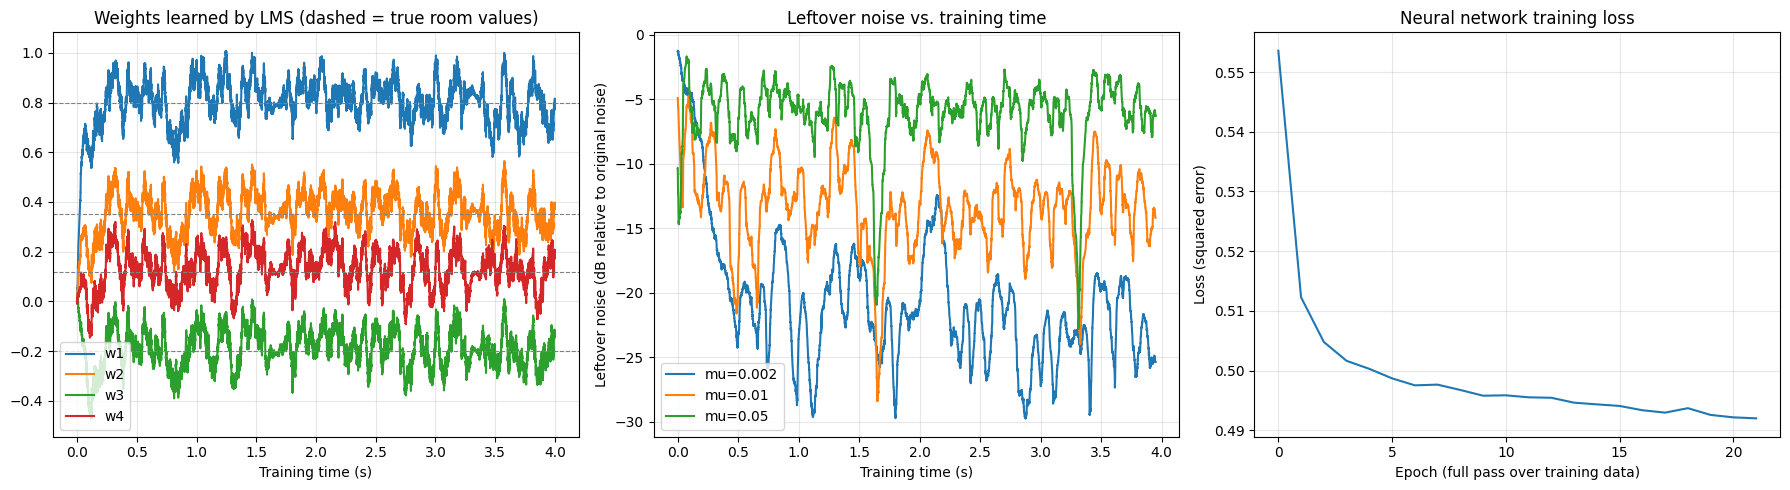

True room weights      : [ 0.8   0.35 -0.2   0.12 -0.07  0.04 -0.02  0.01]
Learned LMS weights    : [ 0.814  0.395 -0.134  0.173 -0.04   0.042 -0.027 -0.011]


In [ ]:
sig = SIG["linear"]; k = sig["split"]
X = delay_matrix(sig["ref"], L)
w, err, hist = lms(X[:k], sig["noisy"][:k], MU)
t = np.arange(k) / SR

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# weights moving towards the true values
for i in range(4):
    ax[0].plot(t, hist[:, i], label=f"w{i+1}")
    ax[0].axhline(H[i], ls="--", color="gray", lw=.8)
ax[0].set_title("Weights learned by LMS (dashed = true room values)")
ax[0].set_xlabel("Training time (s)"); ax[0].legend(); ax[0].grid(alpha=.3)

# how much noise is left, for different learning rates
noise_power = np.mean(sig["noise"] ** 2)
for mu in [0.002, 0.01, 0.05]:
    _, e, _ = lms(X[:k], sig["noisy"][:k], mu)
    resid = (e - sig["clean"][:k]) ** 2
    sm = np.convolve(resid, np.ones(400) / 400, mode="valid")
    ax[1].plot(np.arange(len(sm)) / SR, 10 * np.log10(sm / noise_power + 1e-12), label=f"mu={mu}")
ax[1].set_title("Leftover noise vs. training time"); ax[1].set_xlabel("Training time (s)")
ax[1].set_ylabel("Leftover noise (dB relative to original noise)"); ax[1].legend(); ax[1].grid(alpha=.3)

# the neural network's training loss
_, loss = fit_predict("Neural network", delay_matrix(SIG["nonlinear"]["ref"], L)[:k],
                      SIG["nonlinear"]["noisy"][:k], delay_matrix(SIG["nonlinear"]["ref"], L)[k:k+10])
ax[2].plot(loss); ax[2].set_title("Neural network training loss"); ax[2].set_xlabel("Epoch (full pass over training data)")
ax[2].set_ylabel("Loss (squared error)"); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("True room weights      :", np.round(H, 3))
print("Learned LMS weights    :", np.round(w, 3))

## Part E - Hyper-parameter study - tuning the learning rate of the model
* **Learning rate** too small, model learns slowly and if it's too big the model overshoots and blows up.
* **Filter length** too short, the model is underfits i.e it cannot represent the full range of the noise and if its longer, the model fits but extra weights only add noise.

10. Visualisation of how the learning rate and filter length affect the output of the model

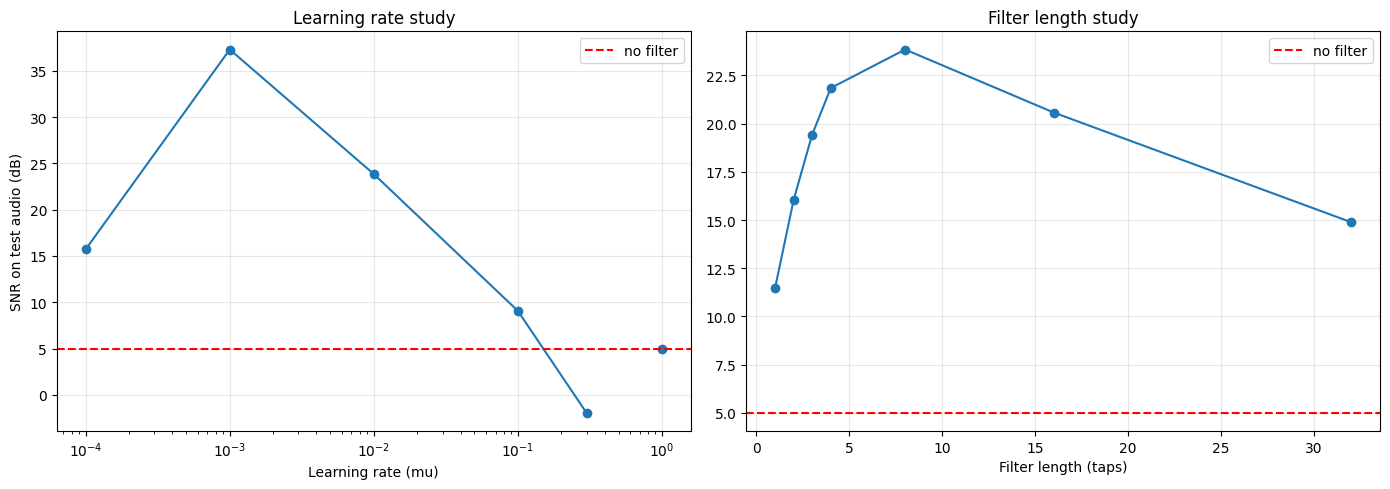

    mu            SNR (dB)
0.0001               15.72
0.0010                37.3
0.0100               23.84
0.1000                9.07
0.3000               -1.96
0.6000 diverged (unstable)
1.0000                4.99


In [ ]:
sig = SIG["linear"]; k = sig["split"]; d, c = sig["noisy"], sig["clean"]

mus = [1e-4, 1e-3, 1e-2, 1e-1, 0.3, 0.6, 1.0]
X = delay_matrix(sig["ref"], L)
res_mu = []
for mu in mus:
    pred, _ = fit_predict("LMS", X[:k], d[:k], X[k:], mu)
    s = snr_db(c[k:], d[k:] - pred)
    res_mu.append(s if (np.isfinite(s) and s > -30) else np.nan)

lens = [1, 2, 3, 4, 8, 16, 32]
res_len = []
for length in lens:
    Xl = delay_matrix(sig["ref"], length)
    pred, _ = fit_predict("LMS", Xl[:k], d[:k], Xl[k:], MU)
    res_len.append(snr_db(c[k:], d[k:] - pred))

base = snr_db(c[k:], d[k:])
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].semilogx(mus, res_mu, "o-"); ax[0].axhline(base, color="r", ls="--", label="no filter")
ax[0].set_xlabel("Learning rate (mu)"); ax[0].set_ylabel("SNR on test audio (dB)"); ax[0].set_title("Learning rate study"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(lens, res_len, "o-"); ax[1].axhline(base, color="r", ls="--", label="no filter")
ax[1].set_xlabel("Filter length (taps)"); ax[1].set_title("Filter length study"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print(pd.DataFrame({"mu": mus, "SNR (dB)": np.round(res_mu, 2)}).fillna("diverged (unstable)").to_string(index=False))

## Part F - Listen to the results and save them

11. Final output audio in WAV format

In [ ]:
for kind in ["linear", "nonlinear"]:
    k = SIG[kind]["split"]
    scale = 1 / max(np.max(np.abs(SIG[kind]["noisy"][k:])), np.max(np.abs(OUT[kind]["LMS"])),
                    np.max(np.abs(OUT[kind]["Neural network"])))
    print(f"\n########## {kind.upper()} NOISE ##########")
    for label, x in [("1) CLEAN original", SIG[kind]["clean"][k:]),
                     ("2) NOISY input", SIG[kind]["noisy"][k:]),
                     ("3) After LMS", OUT[kind]["LMS"]),
                     ("4) After Neural network", OUT[kind]["Neural network"])]:
        print(label); play(x, scale)
        sf.write(f"{kind}_{label[3:].replace(' ', '_')}.wav", np.nan_to_num(x) * scale, SR)
print("\nWAV files saved in the Colab file panel (left sidebar).")


########## LINEAR NOISE ##########
1) CLEAN original


2) NOISY input


3) After LMS


4) After Neural network



########## NONLINEAR NOISE ##########
1) CLEAN original


2) NOISY input


3) After LMS


4) After Neural network



WAV files saved in the Colab file panel (left sidebar).


## Part G - Live Interactive Demo using Gradio

In [ ]:
import gradio as gr

def gradio_fn(audio_path, noise_path, kind, method, mu, snr):
    if audio_path is None:
        return None, None, "Please upload a clean audio file first."
    sig = build_scenario(load_audio(audio_path), kind, snr, noise_file=noise_path)
    k = sig["split"]; X = delay_matrix(sig["ref"], L)
    pred, _ = fit_predict(method, X[:k], sig["noisy"][:k], X[k:], mu)
    noisy, out, c = sig["noisy"][k:], sig["noisy"][k:] - pred, sig["clean"][k:]
    scale = 1 / (max(np.max(np.abs(noisy)), np.max(np.abs(out))) + 1e-9)
    before, after = snr_db(c, noisy), snr_db(c, out)
    text = (f"Method: {method}\nSNR before: {before:.2f} dB\nSNR after : {after:.2f} dB\n"
            f"Improvement: {after - before:.2f} dB")
    return (SR, (noisy * scale).astype(np.float32)), (SR, (out * scale).astype(np.float32)), text

demo = gr.Interface(
    fn=gradio_fn,
    inputs=[gr.Audio(type="filepath", label="Clean audio (music/speech)"),
            gr.Audio(type="filepath", label="Optional: real noise recording"),
            gr.Radio(["linear", "nonlinear"], value="linear", label="Noise type"),
            gr.Dropdown(["LMS", "NLMS", "RLS", "Linear regression", "Neural network"], value="LMS", label="Method"),
            gr.Slider(0.0005, 1.0, value=0.01, label="Learning rate (only for LMS / NLMS)"),
            gr.Slider(-5, 20, value=5, label="Input SNR (dB): lower = noisier")],
    outputs=[gr.Audio(label="Noisy input"), gr.Audio(label="Cleaned output"), gr.Textbox(label="Result")],
    title="Adaptive Noise Cancellation: LMS vs Machine Learning")
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b397927d10496cb663.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
